# Exploración de las series diarias de Tsuchiori

Las cinco métricas comparten un eje de fechas y cada panel tiene su propia escala vertical. La línea punteada señala el **26 de agosto de 2026**, día del máximo de las cinco series.

[Diccionario de datos](diccionario_de_datos.md) · [Notebook de análisis topológico](01_topologia_pagina.ipynb)

Las gráficas ya están guardadas. Para recalcularlas, ejecuta las celdas en orden con un kernel Python 3 y **Rscript** disponible.

In [1]:
import csv
from datetime import date, timedelta
from pathlib import Path

candidatos = (Path.cwd(), Path.cwd().parent)
raiz = next((p for p in candidatos if (p / "datos/transformados/series_diarias_pagina.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abre el notebook desde Página o desde la raíz del proyecto.")
fuente = raiz / "datos/transformados/series_diarias_pagina.csv"
metricas = {
    "pagina_visualizaciones": "Visualizaciones",
    "pagina_espectadores": "Espectadores",
    "pagina_interacciones": "Interacciones",
    "pagina_visitas": "Visitas",
    "pagina_seguidores_metrica_diaria": "Métrica diaria de seguidores",
}
with fuente.open(encoding="utf-8-sig", newline="") as archivo:
    filas = list(csv.DictReader(archivo))
fechas = [date.fromisoformat(fila["fecha"]) for fila in filas]
if not fechas or any(b - a != timedelta(days=1) for a, b in zip(fechas, fechas[1:])):
    raise ValueError("Se espera una fila por día en orden cronológico.")
series = {clave: [int(fila[clave]) for fila in filas] for clave in metricas}
inicio_activo = next(fecha for i, fecha in enumerate(fechas) if any(v[i] > 0 for v in series.values()))
print(f"{len(fechas)} días entre {fechas[0]} y {fechas[-1]}")
print(f"Primer día con actividad en alguna de las cinco métricas: {inicio_activo}")
print()
for clave, nombre in metricas.items():
    valores = series[clave]
    maximo = max(valores)
    print(f"{nombre}: máximo de {maximo:,} el {fechas[valores.index(maximo)]} · {valores.count(0)} días en cero")


315 días entre 2026-01-01 y 2026-11-11
Primer día con actividad en alguna de las cinco métricas: 2026-04-08

Visualizaciones: máximo de 911,216 el 2026-08-26 · 97 días en cero
Espectadores: máximo de 543,378 el 2026-08-26 · 97 días en cero
Interacciones: máximo de 64,134 el 2026-08-26 · 98 días en cero
Visitas: máximo de 3,498 el 2026-08-26 · 105 días en cero
Métrica diaria de seguidores: máximo de 2,398 el 2026-08-26 · 108 días en cero


## Periodo completo en unidades originales

El tramo inicial contiene ceros registrados. La escala lineal conserva la magnitud del pico de agosto y permite comparar cada serie con su propio máximo.

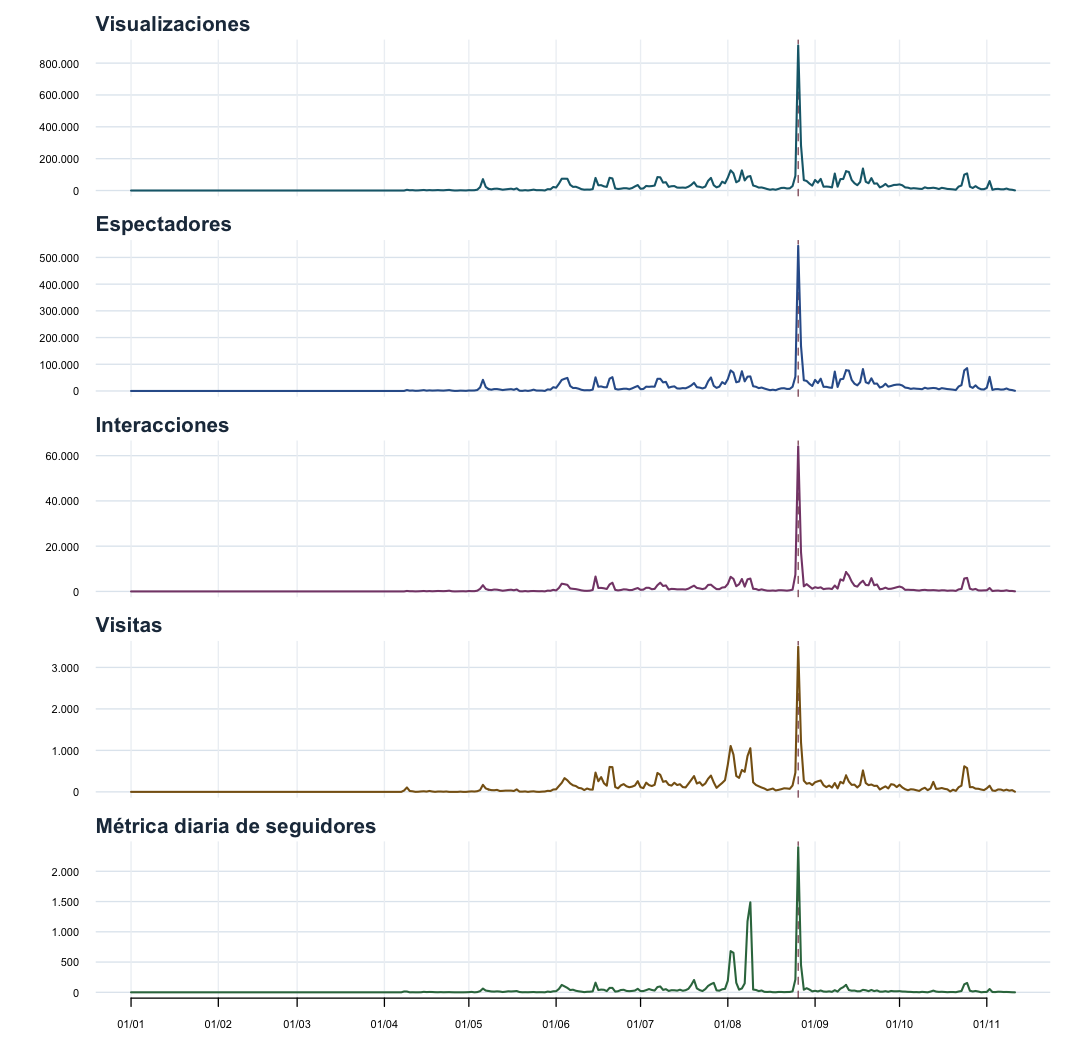

In [2]:

import subprocess
from tempfile import TemporaryDirectory

script_r = r"""
args <- commandArgs(trailingOnly = TRUE)
datos <- read.csv(args[1], fileEncoding = "UTF-8-BOM")
datos$fecha <- as.Date(datos$fecha)
datos <- datos[datos$fecha >= as.Date(args[3]) & datos$fecha <= as.Date(args[4]), ]
stopifnot(nrow(datos) >= 2)
campos <- strsplit(args[6], "|", fixed = TRUE)[[1]]
titulos <- strsplit(args[7], "|", fixed = TRUE)[[1]]
colores <- c("#176879", "#315e99", "#854777", "#876016", "#34754d")
png(args[2], width = 1080, height = 1060, res = 125, type = "quartz")
par(mfrow = c(5,1), mar = c(0.65, 5.8, 2, 1.8), oma = c(3.1,0,0.4,0), las = 1)
marcas <- seq(as.Date(format(min(datos$fecha), "%Y-%m-01")), max(datos$fecha), by = "month")
marcas <- marcas[marcas >= min(datos$fecha)]
for (i in seq_along(campos)) {
    valor <- datos[[campos[i]]]
    if (args[5] == "log1p") valor <- log1p(valor)
    plot(datos$fecha, valor, type = "n", ylim = c(0, max(1, valor)), axes = FALSE, xlab = "", ylab = "")
    ticks <- pretty(c(0, max(1, valor)), n = 4)
    ticks <- ticks[ticks <= max(1, valor)]
    abline(h = ticks, col = "#e0e8ef")
    abline(v = as.numeric(marcas), col = "#edf1f5")
    abline(v = as.numeric(as.Date("2026-08-26")), col = "#8c5362", lty = 2)
    lines(datos$fecha, valor, col = colores[i], lwd = 1.6)
    axis(2, at = ticks, labels = format(ticks, big.mark = ".", decimal.mark = ",", scientific = FALSE),
         tick = FALSE, cex.axis = 0.8)
    mtext(titulos[i], side = 3, adj = 0, line = 0.35, font = 2, col = "#20364a")
    if (i == length(campos)) axis.Date(1, at = marcas, format = "%d/%m", cex.axis = 0.8)
}
invisible(dev.off())
"""

def graficar(desde, hasta, escala="lineal"):
    if escala not in {"lineal", "log1p"}:
        raise ValueError("Usa lineal o log1p.")
    with TemporaryDirectory() as tmp:
        salida = Path(tmp) / "series.png"
        programa = Path(tmp) / "grafica.R"
        programa.write_text(script_r, encoding="utf-8")
        ejecucion = subprocess.run(
            ["Rscript", str(programa), str(fuente), str(salida), str(desde), str(hasta),
             escala, "|".join(metricas), "|".join(metricas.values())],
            check=True, capture_output=True, text=True
        )
        if not salida.exists():
            raise RuntimeError(ejecucion.stdout + ejecucion.stderr)
        return salida.read_bytes()

def mostrar(imagen):
    from IPython.display import Image, display
    display(Image(data=imagen, width=870))

figura_completa = graficar(fechas[0], fechas[-1])
mostrar(figura_completa)


## Tramo con actividad en escala logarítmica

La transformación **log(1 + x)** comprime los picos y conserva los ceros. Los valores del eje vertical están en esa escala. Edita las fechas para ampliar un episodio, como el repunte de junio o el de agosto.

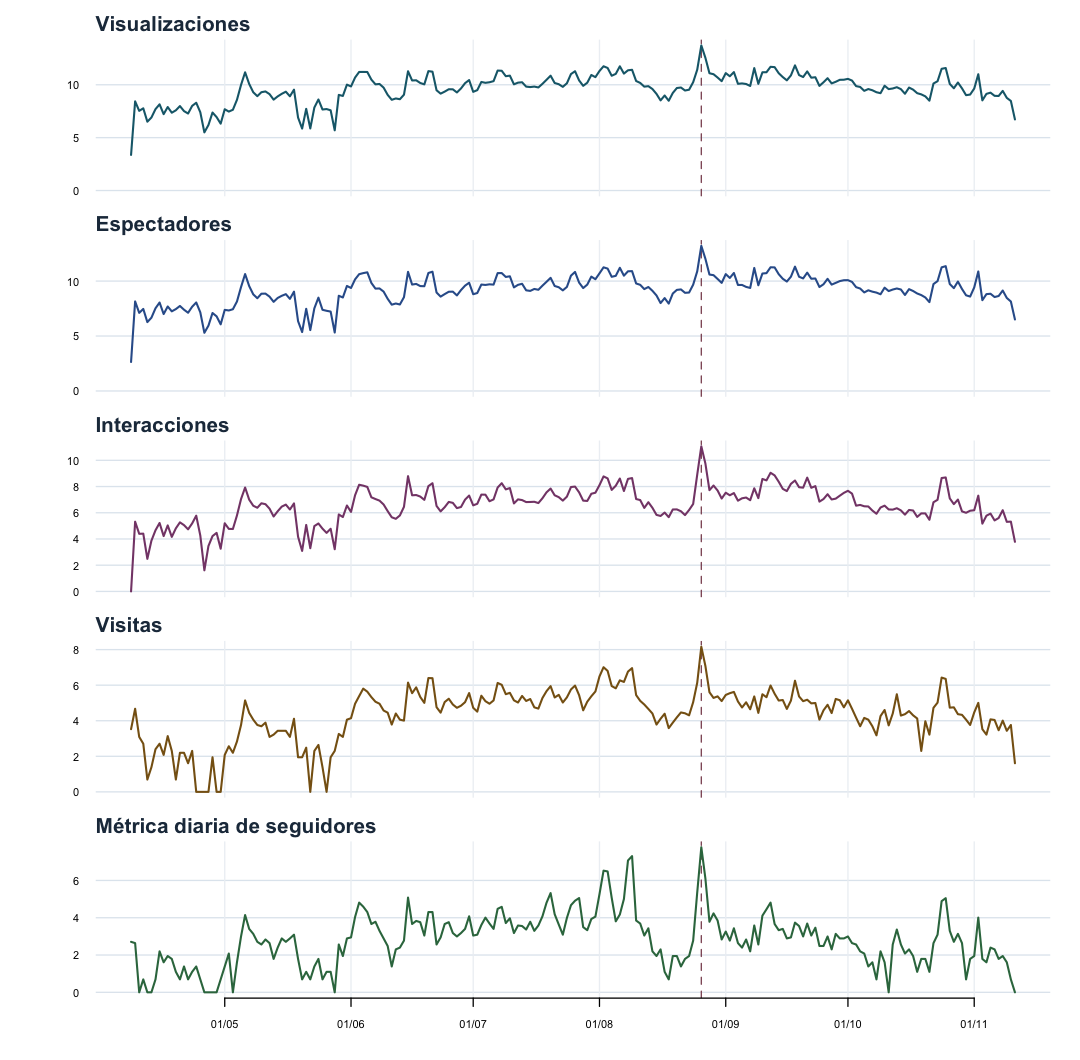

In [3]:
desde = inicio_activo  # Por ejemplo, "2026-06-01".
hasta = fechas[-1]    # Por ejemplo, "2026-06-30".
figura_activa = graficar(desde, hasta, escala="log1p")
mostrar(figura_activa)


## Cambios topológicos en las visualizaciones

Cada punto de Takens contiene las visualizaciones de siete días consecutivos en escala `log(1 + x)`. Agrupamos 28 puntos consecutivos para formar una nube con 34 días de datos originales. Calculamos diagramas de Vietoris–Rips para componentes conexas ($H_0$) y ciclos ($H_1$). La distancia Wasserstein de orden 1 compara cada diagrama con el de la ventana anterior.

El tramo principal incluye solamente comparaciones en las que **ambas ventanas** empiezan el 8 de abril o después. El cambio absoluto de la media móvil usa el mismo soporte de 34 días y la misma escala. Cada panel tiene su propia escala vertical. La línea punteada marca el 16 de junio.


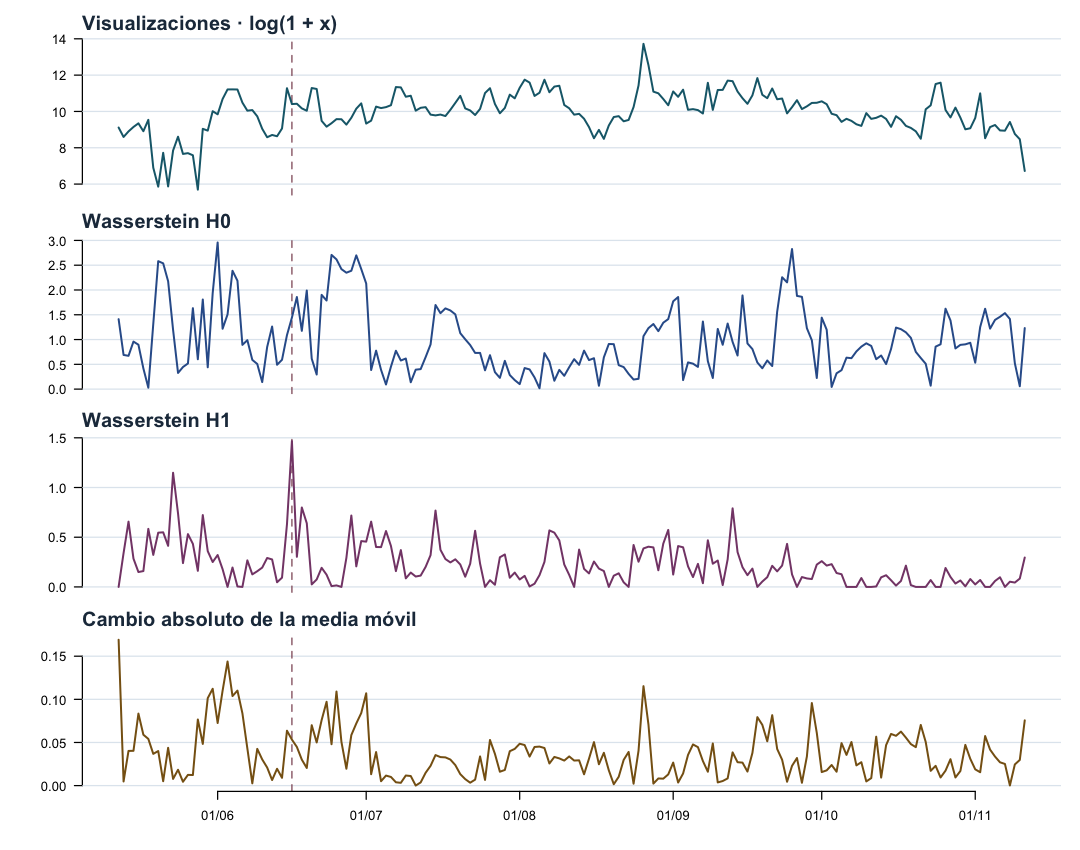

wasserstein_h0: máximo el 2026-06-01 (2.958)
wasserstein_h1: máximo el 2026-06-16 (1.467)
cambio_abs_media: máximo el 2026-05-12 (0.169)
184 comparaciones en el tramo activo y 281 en todo el periodo
Máximo de H₀ con ceros iniciales: 2026-05-11


In [4]:
import json

carpeta_tda = raiz / "enfoque_topologico"
with (carpeta_tda / "distancias.csv").open(encoding="utf-8", newline="") as archivo:
    distancias = list(csv.DictReader(archivo))
referencia = [fila for fila in distancias
              if (fila["dimension"], fila["puntos"]) == ("7", "28")
              and fila["wasserstein_h1"]]
serie_log = [fila for fila in referencia if fila["escala"] == "log1p"]
activas = [actual for anterior, actual in zip(serie_log, serie_log[1:])
           if date.fromisoformat(anterior["inicio_ventana"]) >= inicio_activo]

def figura_tda(programa, datos, ancho, alto):
    with TemporaryDirectory() as temporal:
        temporal = Path(temporal)
        entrada = temporal / "entrada.csv"
        with entrada.open("w", encoding="utf-8", newline="") as archivo:
            escritor = csv.DictWriter(archivo, fieldnames=list(datos[0]))
            escritor.writeheader()
            escritor.writerows(datos)
        codigo = temporal / "figura.R"
        codigo.write_text(programa, encoding="utf-8")
        salida = temporal / "figura.png"
        subprocess.run(["Rscript", str(codigo), str(entrada), str(salida), str(ancho), str(alto)],
                       check=True, capture_output=True, text=True)
        return salida.read_bytes()

r_inicio = """
args <- commandArgs(trailingOnly = TRUE)
d <- read.csv(args[1], fileEncoding = "UTF-8")
png(args[2], width = as.integer(args[3]), height = as.integer(args[4]), res = 120,
    type = if (Sys.info()[["sysname"]] == "Darwin") "quartz" else "cairo")
"""

figura = figura_tda(r_inicio + """
d$fecha <- as.Date(d$fecha)
par(mfrow=c(4,1), mar=c(0.7,5.2,1.9,1.2), oma=c(3,0,0.5,0), las=1)
series <- list(log1p(d$visualizaciones), d$wasserstein_h0, d$wasserstein_h1, d$cambio_abs_media)
titulos <- c("Visualizaciones · log(1 + x)", "Wasserstein H0", "Wasserstein H1", "Cambio absoluto de la media móvil")
colores <- c("#176879", "#315e99", "#854777", "#876016")
for (i in seq_along(series)) {
    plot(d$fecha, series[[i]], type="n", xaxt="n", xlab="", ylab="", bty="n")
    abline(h=axTicks(2), col="#e0e8ef")
    abline(v=as.Date("2026-06-16"), lty=2, col="#8c5362")
    lines(d$fecha, series[[i]], col=colores[i], lwd=1.6)
    mtext(titulos[i], side=3, adj=0, line=0.35, font=2, col="#20364a")
    if (i == 4) axis.Date(1, d$fecha, format="%d/%m")
}
invisible(dev.off())
""", activas, 1080, 850)
mostrar(figura)

for campo in ("wasserstein_h0", "wasserstein_h1", "cambio_abs_media"):
    mayor = max(activas, key=lambda fila: float(fila[campo]))
    print(f"{campo}: máximo el {mayor['fecha']} ({float(mayor[campo]):.3f})")
print(f"{len(activas)} comparaciones en el tramo activo y {len(serie_log)} en todo el periodo")
print("Máximo de H₀ con ceros iniciales:", max(serie_log, key=lambda f: float(f["wasserstein_h0"]))["fecha"])


El máximo de **H₀** cae el **1 de junio** en el tramo activo y el **11 de mayo** en la serie completa. La ventana que cierra el 11 de mayo empieza el 8 de abril, justo cuando su soporte deja atrás los ceros iniciales. El máximo de **H₁** se mantiene el **16 de junio**.

## Diagramas del 15 al 17 de junio

Cada punto marca el nacimiento y la muerte de un ciclo en la filtración. Una mayor separación de la diagonal indica mayor persistencia. Los paneles comparten escala.

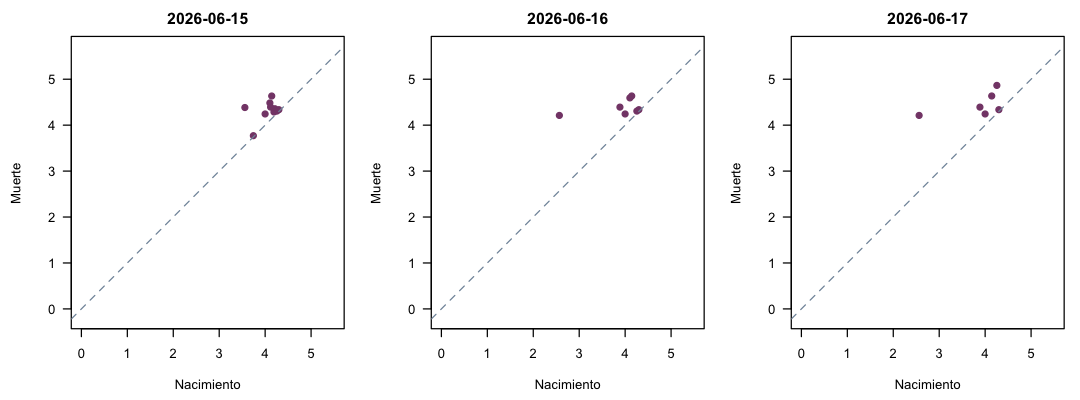

2026-06-15 · persistencia máxima 0.825 · Wasserstein H₁ —
2026-06-16 · persistencia máxima 1.644 · Wasserstein H₁ 1.467
2026-06-17 · persistencia máxima 1.649 · Wasserstein H₁ 0.303


In [5]:
episodio = json.loads((carpeta_tda / "episodio_junio.json").read_text(encoding="utf-8"))
escenario = "observada"  # Cambia a "pico_sustituido" para repetir la comparación.
diagramas = episodio[escenario]
puntos = [dict(fecha=registro["fecha"], nacimiento=nacimiento, muerte=muerte)
          for registro in diagramas for nacimiento, muerte in registro["diagrama_h1"]]

figura = figura_tda(r_inicio + """
par(mfrow=c(1,3), mar=c(4.5,4.5,2.3,1), las=1)
limite <- c(0, 5.5)
for (fecha in unique(d$fecha)) {
    panel <- d[d$fecha == fecha, ]
    plot(panel$nacimiento, panel$muerte, xlim=limite, ylim=limite, asp=1,
         xlab="Nacimiento", ylab="Muerte", main=fecha, pch=19, col="#854777")
    abline(0,1, col="#8194a8", lty=2)
}
invisible(dev.off())
""", puntos, 1080, 400)
mostrar(figura)
for registro in diagramas:
    maxima = max(muerte - nacimiento for nacimiento, muerte in registro["diagrama_h1"])
    distancia = registro["wasserstein_h1"]
    comparacion = "—" if distancia is None else f"{distancia:.3f}"
    print(f"{registro['fecha']} · persistencia máxima {maxima:.3f} · Wasserstein H₁ {comparacion}")


La persistencia máxima pasó de **0,825 a 1,644** del 15 al 16. Al sustituir las 79.127 visualizaciones del 15 por la mediana local de 19.877, la distancia del 16 bajó de **1,467 a 1,164** y la del 17 subió de **0,303 a 1,019**. El cambio sigue siendo visible y su distribución entre fechas depende del pico. Los ciclos describen la geometría de las ventanas. La periodicidad de la serie requiere otra comprobación.

## El pico de agosto en dos escalas

La línea punteada marca el 26 de agosto. Cada panel usa su propia escala vertical porque las distancias calculadas sobre conteos y sobre logaritmos tienen escalas diferentes. Compara la fecha y la prominencia relativa de los picos dentro de cada panel.

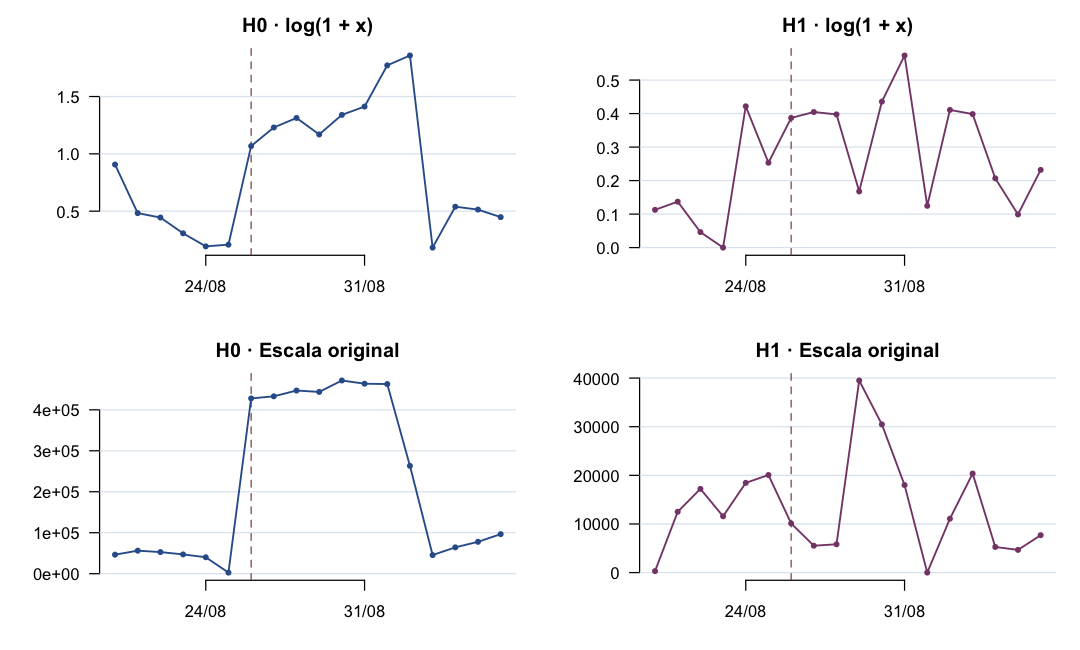

log1p · 26 de agosto · puesto 95 de 281 en H₀
bruto · 26 de agosto · puesto 12 de 281 en H₀


In [6]:
agosto = [fila for fila in referencia if fila["escala"] in {"log1p", "bruto"}
          and "2026-08-20" <= fila["fecha"] <= "2026-09-06"]
figura = figura_tda(r_inicio + """
d$fecha <- as.Date(d$fecha)
par(mfrow=c(2,2), mar=c(3.5,5,2.4,1.2), las=1)
for (escala in c("log1p", "bruto")) {
    panel <- d[d$escala == escala, ]
    nombre <- if (escala == "bruto") "Escala original" else "log(1 + x)"
    for (dimension in c("h0", "h1")) {
        valor <- panel[[paste0("wasserstein_", dimension)]]
        plot(panel$fecha, valor, type="n", xaxt="n", xlab="", ylab="", bty="n",
             main=paste(if (dimension=="h0") "H0" else "H1", nombre, sep=" · "))
        axis.Date(1, panel$fecha, format="%d/%m")
        abline(h=axTicks(2), col="#e0e8ef")
        abline(v=as.Date("2026-08-26"), col="#8c5362", lty=2)
        lines(panel$fecha, valor, col=if (dimension=="h0") "#315e99" else "#854777",
              type="o", pch=19, cex=0.55, lwd=1.5)
    }
}
invisible(dev.off())
""", agosto, 1080, 650)
mostrar(figura)
for escala in ("log1p", "bruto"):
    orden = sorted((fila for fila in referencia if fila["escala"] == escala),
                   key=lambda fila: float(fila["wasserstein_h0"]), reverse=True)
    puesto = next(i for i, fila in enumerate(orden, 1) if fila["fecha"] == "2026-08-26")
    print(f"{escala} · 26 de agosto · puesto {puesto} de {len(orden)} en H₀")


El 26 de agosto sube del **puesto 95 al 12 en H₀** al pasar del logaritmo a la escala original, usando las 281 comparaciones disponibles en cada escala. En escala original, los dos cambios más grandes de **H₁** llegaron el 29 y el 30. Una misma observación aparece en varios vectores retardados y su efecto puede extenderse a varios cierres.

[Metodología y código](../enfoque_topologico/README.md) · [Análisis del episodio de junio](../enfoque_topologico/episodio_junio.md)

Para regenerar los resultados topológicos, ejecuta desde la raíz del proyecto `python3 enfoque_topologico/analisis.py` y luego `python3 enfoque_topologico/episodio_junio.py`. Las figuras de este notebook se construyen a partir de esas salidas.


## Cambios conjuntos en las cinco métricas

El análisis anterior estudia la forma de las visualizaciones. Aquí cada vector de Takens reúne siete días de cada métrica. Aplicamos log(1 + x) y dividimos por el rango intercuartílico de cada serie en el tramo activo. Comparamos visualizaciones solas, las cinco métricas juntas y un conjunto de interacciones, visitas y seguidores. Cada panel usa su propia escala vertical. La línea marca el 29 de agosto.


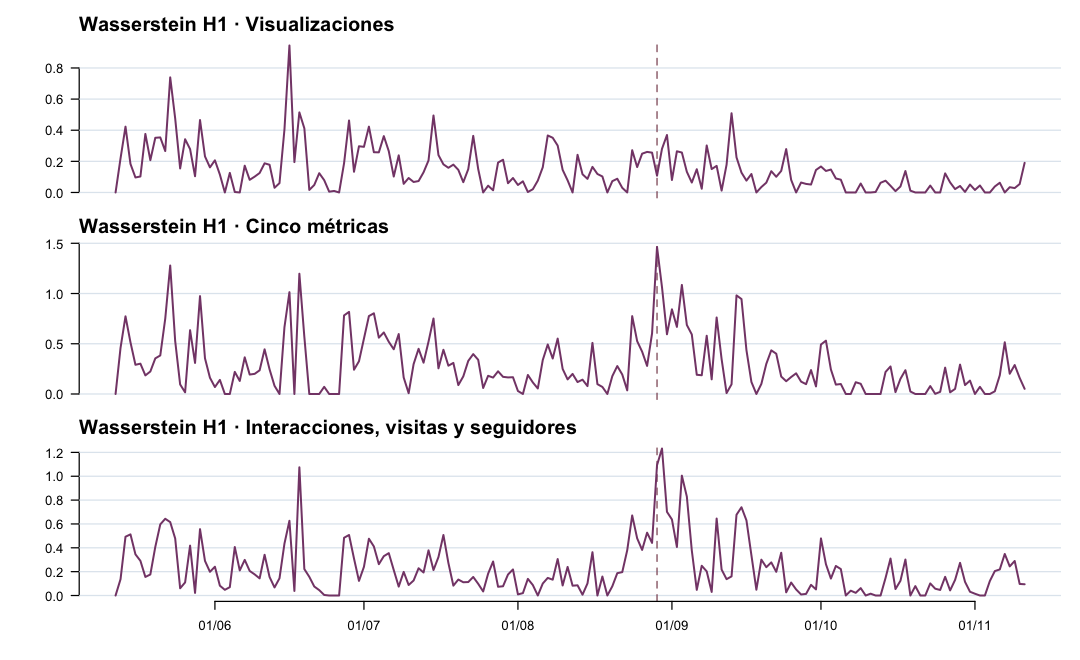

In [7]:
with (raiz / "Página/distancias_multivariadas.csv").open(encoding="utf-8", newline="") as archivo:
    conjunta = list(csv.DictReader(archivo))
figura = figura_tda(r_inicio + """
d$fecha <- as.Date(d$fecha)
par(mfrow=c(3,1), mar=c(0.7,5,2,1.2), oma=c(3,0,0.5,0), las=1)
grupos <- unique(d$conjunto)
titulos <- c("Visualizaciones", "Cinco métricas", "Interacciones, visitas y seguidores")
for (i in seq_along(grupos)) {
    panel <- d[d$conjunto == grupos[i], ]
    plot(panel$fecha, panel$wasserstein_h1, type="n", xaxt="n", xlab="", ylab="", bty="n")
    abline(h=axTicks(2), col="#e0e8ef")
    abline(v=as.Date("2026-08-29"), lty=2, col="#8c5362")
    lines(panel$fecha, panel$wasserstein_h1, col="#854777", lwd=1.6)
    mtext(paste("Wasserstein H1 ·", titulos[i]), side=3, adj=0, line=0.35, font=2)
    if (i == 3) axis.Date(1, panel$fecha, format="%d/%m")
}
invisible(dev.off())
""", conjunta, 1080, 660)
mostrar(figura)


El 29 de agosto quedó en el puesto **92 de 184** con visualizaciones solas y en el **primero** con las cinco métricas. Al usar interacciones, visitas y seguidores, el máximo cayó el 30 y el 29 quedó segundo. Esto sitúa el episodio en la respuesta conjunta del público alrededor del pico de agosto. Las ventanas cerradas el 29 y el 30 aún incluyen el 26. El método destaca un cambio en la forma de las trayectorias recientes, con una fecha que depende de las variables incluidas.

La comparación es exploratoria. Visualizaciones y espectadores pueden aportar información relacionada. La variante de tres métricas comprueba si el episodio sigue destacando al retirar ambas. Para reproducir, ejecuta `python3 Página/topologia_multivariada.py` desde la raíz del proyecto.


## Aporte predictivo de la topología

Dos modelos Ridge con el mismo historial de cinco métricas se evaluaron en 162 cortes cronológicos. Añadir Wasserstein H₀ y H₁ cambió el MAE de **24.809,97 a 24.798,26**. Al retirar solo el error del 26 de agosto, el MAE pasó de **19.636,14 a 19.639,75**. La contribución descriptiva de TDA tiene un resultado más claro que la mejora predictiva en esta prueba.

[Protocolo, código y predicciones](validacion_predictiva.md)